# Explore here

In [1]:
# Librerías 

import pandas as pd

df = pd.read_csv('https://breathecode.herokuapp.com/asset/internal-link?id=930&path=diabetes.csv')

df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
df.shape

(768, 9)

In [3]:
df.info(verbose=True)

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


Vemos que en total hay un total de 768 filas en nuestro dataset y 9 columnas. También vemos que no hay datos nulos en las columanas y que todas son de tipo numéricas.

In [33]:
df[df['Insulin'] == 0]


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
5,5,116,74,0,0,25.6,0.201,30,0
7,10,115,0,0,0,35.3,0.134,29,0
...,...,...,...,...,...,...,...,...,...
761,9,170,74,31,0,44.0,0.403,43,1
762,9,89,62,0,0,22.5,0.142,33,0
764,2,122,70,27,0,36.8,0.340,27,0
766,1,126,60,0,0,30.1,0.349,47,1


In [34]:
df[df['Insulin'] > 0]

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1
6,3,78,50,32,88,31.0,0.248,26,1
8,2,197,70,45,543,30.5,0.158,53,1
13,1,189,60,23,846,30.1,0.398,59,1
...,...,...,...,...,...,...,...,...,...
753,0,181,88,44,510,43.3,0.222,26,1
755,1,128,88,39,110,36.5,1.057,37,1
760,2,88,58,26,16,28.4,0.766,22,0
763,10,101,76,48,180,32.9,0.171,63,0


hacer un mini modelo para predecir Insulin. Aarbol de decisión. 

Ahora vamos a chequear que no haya duplicados:

Acá deberíamos hacer un EDA. Son todas numéricas las variables, por lo que sólo hay que hacer un análisis numérico-numérico y análsis multivariado, para poder entender las características. Vemos que 'Insulina' es un muy buen predictor pero hay muchos datos en 0 (que no se tomó la medición) por lo que deberíamos hacer una imputación de variables. Eso lo tenemos que decidir dentro del EDA. 

Entonces acá hay 3 cosas que deberíamos hacer:
- Análisis numérico-numérico
- Análisis multivariado
- Imputación de variables que están en cero.

RECORDAR: Al momento de hacer el EDA en este modelo (ÁRBOL DE DECISION), no hay que hacer normalización de variables ni tampoco transformación de variables categóricas a numéricas si las hubiese.



## 1. Eliminar información irrelevante

En este caso vemos que todas las predictoras son, en principio, importantes/relevantes para el problema a predecir. No contamos con un 'Id', o una columna de 'names' o similar que contengan información no relevante para la predicción, asique por el momento las vamos a dejar a todas. 

## 2. Análisis de variables univariante

Vamos a hacer un análisis de tipo NUMÉRICO-NUMÉRICO, ya que todas las variables lo son. 

In [5]:
df.columns.tolist()

['Pregnancies',
 'Glucose',
 'BloodPressure',
 'SkinThickness',
 'Insulin',
 'BMI',
 'DiabetesPedigreeFunction',
 'Age',
 'Outcome']

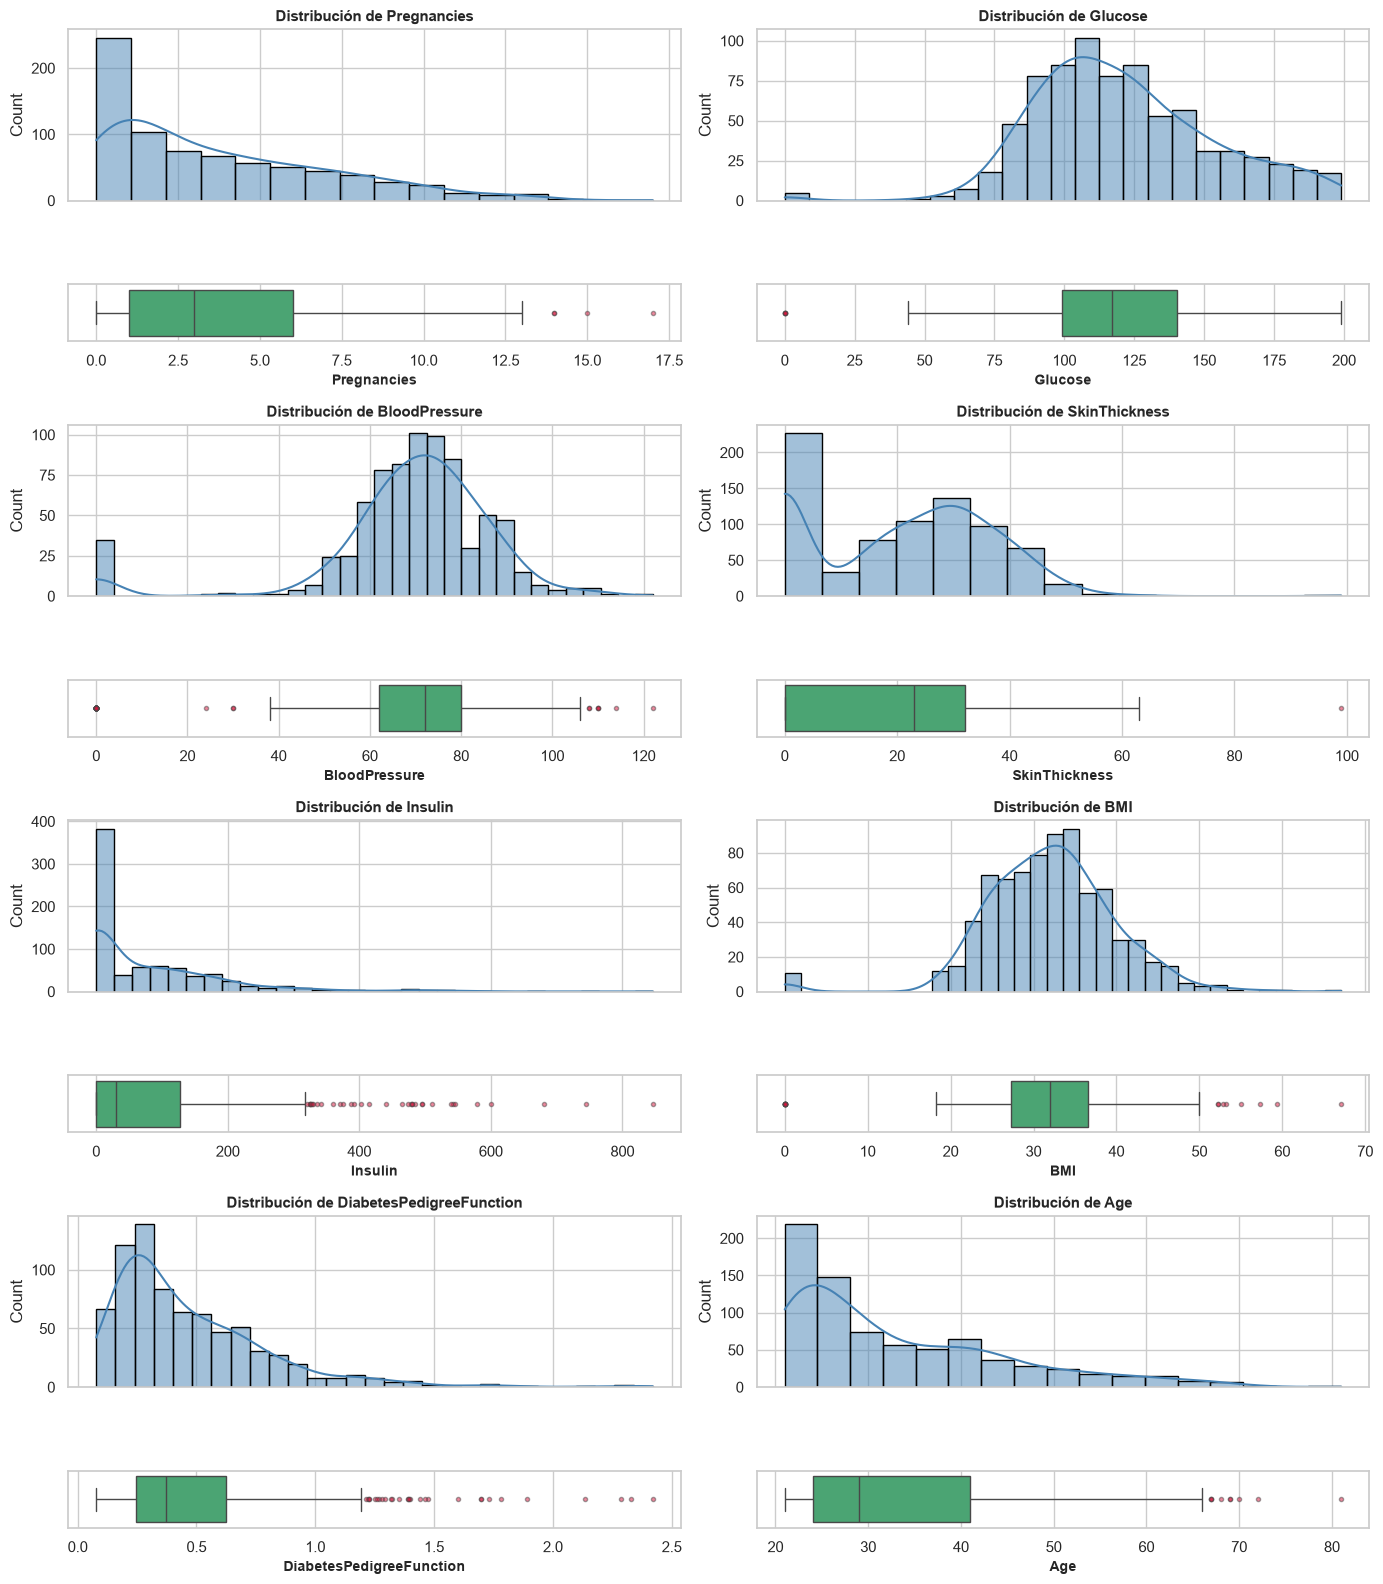

In [6]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# Definición de la lista de variables numéricas
numericas = [
    'Pregnancies', 
    'Glucose', 
    'BloodPressure', 
    'SkinThickness', 
    'Insulin', 
    'BMI', 
    'DiabetesPedigreeFunction', 
    'Age'
]

sns.set_theme(style="whitegrid")

# Configuración de la retícula: 2 columnas x bloques de variables
ncols = 2
num_vars = len(numericas)
num_bloques = math.ceil(num_vars / ncols)  # Calculado automáticamente según las variables

# Se crean las filas en total (2 filas por cada variable: 1 Histograma + 1 Boxplot)
fig, axes = plt.subplots(
    nrows=num_bloques * 2, 
    ncols=ncols, 
    figsize=(14, 4 * num_bloques), 
    gridspec_kw={'height_ratios': [3, 1] * num_bloques} # El histograma es más alto que el boxplot
)

# Bucle para graficar histograma + boxplot por cada variable
for i, col in enumerate(numericas):
    row_hist = (i // ncols) * 2  # Fila para el histograma
    c = i % ncols               # Columna (0 o 1)
    row_box = row_hist + 1       # Fila inmediatamente inferior para el boxplot
    
    ax_hist = axes[row_hist, c]
    ax_box = axes[row_box, c]
    
    # 1. Histograma (Arriba)
    sns.histplot(
        data=df, x=col, kde=True, ax=ax_hist, 
        color='steelblue', edgecolor='black'
    )
    ax_hist.set_title(f'Distribución de {col}', fontsize=11, fontweight='bold')
    ax_hist.set_xlabel('')
    ax_hist.tick_params(labelbottom=False)  # Oculta etiquetas numéricas repetidas en X
    
    # 2. Diagrama de caja / Boxplot (Abajo)
    sns.boxplot(
        data=df, x=col, ax=ax_box, color='mediumseagreen',
        flierprops=dict(marker='o', markerfacecolor='crimson', markersize=3, alpha=0.5)
    )
    ax_box.set_xlabel(col, fontsize=10, fontweight='bold')
    
    # Compartir el mismo eje X para asegurar alineación visual perfecta
    ax_hist.sharex(ax_box)

plt.tight_layout()
plt.show()

Del análsis de estos gráficos en conjunto podemos ver que algunas distribuyen normal (como 'Glucose', 'BloodPressure' y 'BMI') y algunas otras están sesgadas hacia la izquierda como 'DiabetesPedigreeFunction', 'Age', 'Insulin', 'Pregnancies' y  'SkinThickness', que distribuye normal pero tmb con un sesgo hacia esa dirección.

Sesgadas a la derecha (asimetría positiva): Variables como Pregnancies, Insulin, DiabetesPedigreeFunction y SkinThickness. Tinen una "cola" larga hacia valores altos. Aproximadamente normales (campana de Gauss): Variables como Glucose, BloodPressure y BMI suelen mostrar una forma más simétrica y centrada.
Valores Cero Anómalos (Valores Imposibles)En este dataset específico, hay picos extraños en el valor 0 para variables biológicas donde un cero es fisiológicamente imposible:Glucose = 0, BloodPressure = 0, BMI = 0, SkinThickness = 0, Insulin = 0. Conclusión clave: Estos ceros no representan mediciones reales, sino datos faltantes o no registrados (NaN). Antes de entrenar un modelo, debemos tratarlos (imputación por la mediana/media o eliminación).

Como nuestro modelo va a ser un árbol de decisión, deberíamos:

- Los Valores Cero (0) SÍ importan (y deben tratarse) El problema: Aunque el árbol tolera diferentes escalas, si una persona tiene Glucose = 0, el árbol interpretará ese 0 como un valor numérico real muy bajo, en lugar de un "dato faltante". Qué buscar: Revisa los picos en cero de Glucose, BloodPressure, BMI, SkinThickness e Insulin.Qué hacer: Debes reemplazarlos por NaN o imputarlos (por ejemplo, con la mediana). Si usas librerías como XGBoost o LightGBM, manejan los datos faltantes de forma nativa, pero un DecisionTreeClassifier básico de scikit-learn lanzará un error si encuentra NaN.

- Los Outliers NO rompen el árbol. La ventaja: A diferencia de una Regresión Logística o Redes Neuronales, los puntos rojos atípicos en el boxplot (como Insulin > 400) no distorsionan el árbol.Cómo lo maneja: Si un punto es extremo, simplemente quedará clasificado en una hoja al final de una rama sin "jalar" ni deformar la lógica del resto de las divisiones. Qué hacer: No necesitas eliminar ni transformar los outliers.

- La Asimetría/Sesgo NO interfiere. La ventaja: Que DiabetesPedigreeFunction o Insulin tengan una cola muy larga a la derecha no afecta el rendimiento del algoritmo.Qué hacer: No apliques transformaciones logarítmicas ni de potencia, Trabaja con los valores brutos.

- Qué SÍ buscar: Capacidad de SeparaciónLo que realmente te interesa observar en los gráficos para un árbol es:Rango útil de valores: Dónde se concentra la mayoría de los datos para entender en qué rango el árbol creará la mayoría de sus divisiones (splits).
- Variables con mayor dispersión: Variables como Glucose o BMI suelen mostrar rangos amplios y bien definidos, lo que sugiere que podrían ser candidatas a aparecer en las primeras divisiones (nodos superiores) del árbol.


## 3. Análsis de variables multivariante

Tras analizar las características una a una, ahora vamos a analizarlas en relación a la predictora/clase y entre ellas mismas, para poder sacar conclusiones más claras en cuanto a sus relaciones. 

Análisi NUMÉRICO-NUMÉRICO





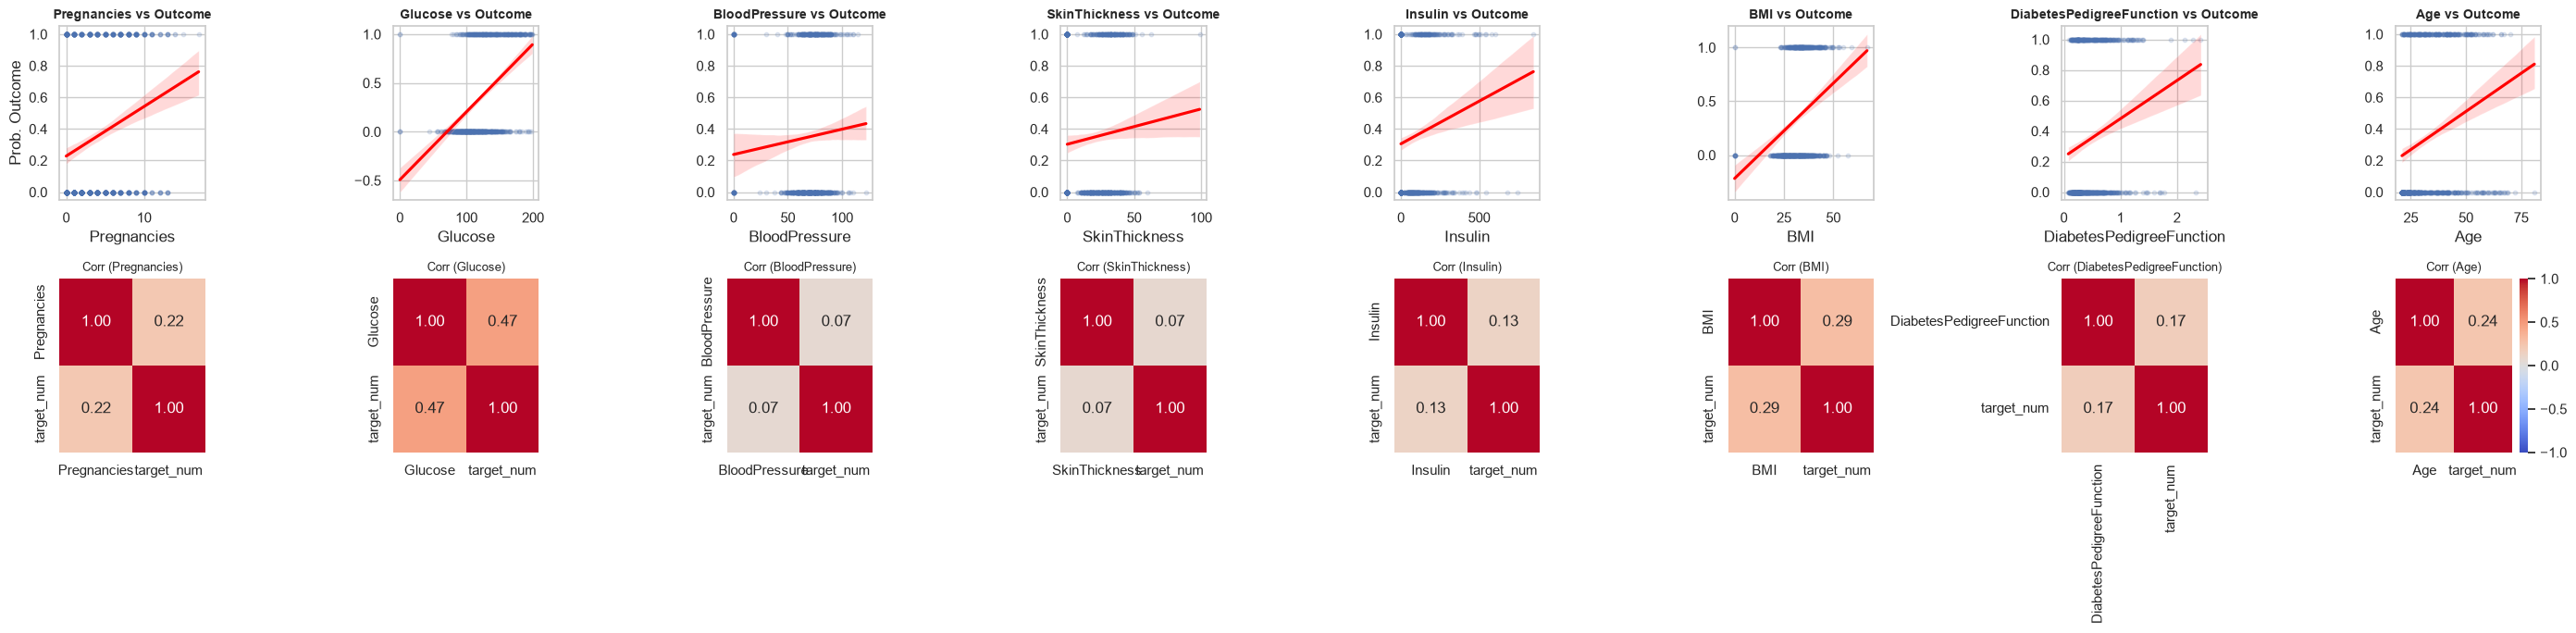

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definir la variable objetivo y las variables numéricas
target_col = 'Outcome'
numericas = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
]

# 2. Copia de trabajo y aseguramiento de 'target_num' en formato 0 / 1
df_plot = df.copy()

if df_plot[target_col].dtype == 'object':
    df_plot['target_num'] = (
        df_plot[target_col]
        .astype(str)
        .str.lower()
        .map({'yes': 1, 'no': 0, '1': 1, '0': 0})
    )
else:
    df_plot['target_num'] = df_plot[target_col]

# 3. Crear el lienzo con 2 filas y tantas columnas como predictores (8)
ncols = len(numericas)
fig, axis = plt.subplots(2, ncols, figsize=(3.5 * ncols, 7))

for i, col in enumerate(numericas):
    # Fila 0: Diagrama de Regresión / Dispersión
    sns.regplot(
        data=df_plot,
        x=col,
        y='target_num',
        ax=axis[0, i],
        scatter_kws={'alpha': 0.15, 's': 10},
        line_kws={'color': 'red'},
    )
    axis[0, i].set_title(
        f'{col} vs {target_col}', fontsize=10, fontweight='bold'
    )
    axis[0, i].set_xlabel(col)
    axis[0, i].set_ylabel(f'Prob. {target_col}' if i == 0 else '')

    # Fila 1: Heatmap de Correlación entre la variable actual y Outcome
    corr_matrix = df_plot[[col, 'target_num']].corr()

    sns.heatmap(
        corr_matrix,
        annot=True,
        fmt='.2f',
        cmap='coolwarm',
        vmin=-1,
        vmax=1,
        ax=axis[1, i],
        cbar=(i == ncols - 1),  # Barra de color únicamente en la última figura
    )
    axis[1, i].set_title(f'Corr ({col})', fontsize=9)

plt.tight_layout()
plt.show()

Principales Hallazgos:

Glucose (Glucosa) es el predictor más fuerte (r = 0.47): Presenta la correlación positiva más alta con la variable objetivo y la pendiente de regresión más pronunciada. A mayor nivel de glucosa, la probabilidad de dar positivo en diabetes se incrementa de forma significativa.

BMI (Índice de Masa Corporal) es el segundo factor determinante (r = 0.29): Muestra una relación lineal positiva clara con el riesgo de padecer la enfermedad. Por ende, a mayor IMC, mayor probabilidad de padecer diabetes.

Age (Edad) y Pregnancies (Embarazos) aportan un riesgo moderado (r = 0.24 y 0.22): Ambas variables crecen juntas y muestran que a mayor edad y mayor número de embarazos, aumenta ligeramente la probabilidad de diagnóstico.

Factores con correlación débil o modesta:

DiabetesPedigreeFunction (r = 0.17) e Insulin (r = 0.13) muestran una tendencia positiva, pero con menor fuerza directa.

BloodPressure (r = 0.07) y SkinThickness (r = 0.07) tienen una correlación casi nula con la variable objetivo de manera lineal individual.

Observaciones Críticas de Calidad de Datos
Presencia de ceros biológicamente imposibles: En gráficos como Glucose, BloodPressure, SkinThickness, Insulin y BMI, existen registros con valor 0. Como una persona no puede tener glucosa o presión arterial de 0, estos ceros corresponden a datos faltantes (NAs) codificados como 0.

Impacto en los modelos: Estos valores cero distorsionan las líneas de regresión (por ejemplo, haciendo que la pendiente de Glucose empiece por debajo de 0). Antes de entrenar un modelo, es imprescindible imputar o limpiar estos datos nulos. **Por ende vamos a cambiar esos ceros por Nan y luego realizar un imputación por la mediana.**

## Combinación de varias predictoras



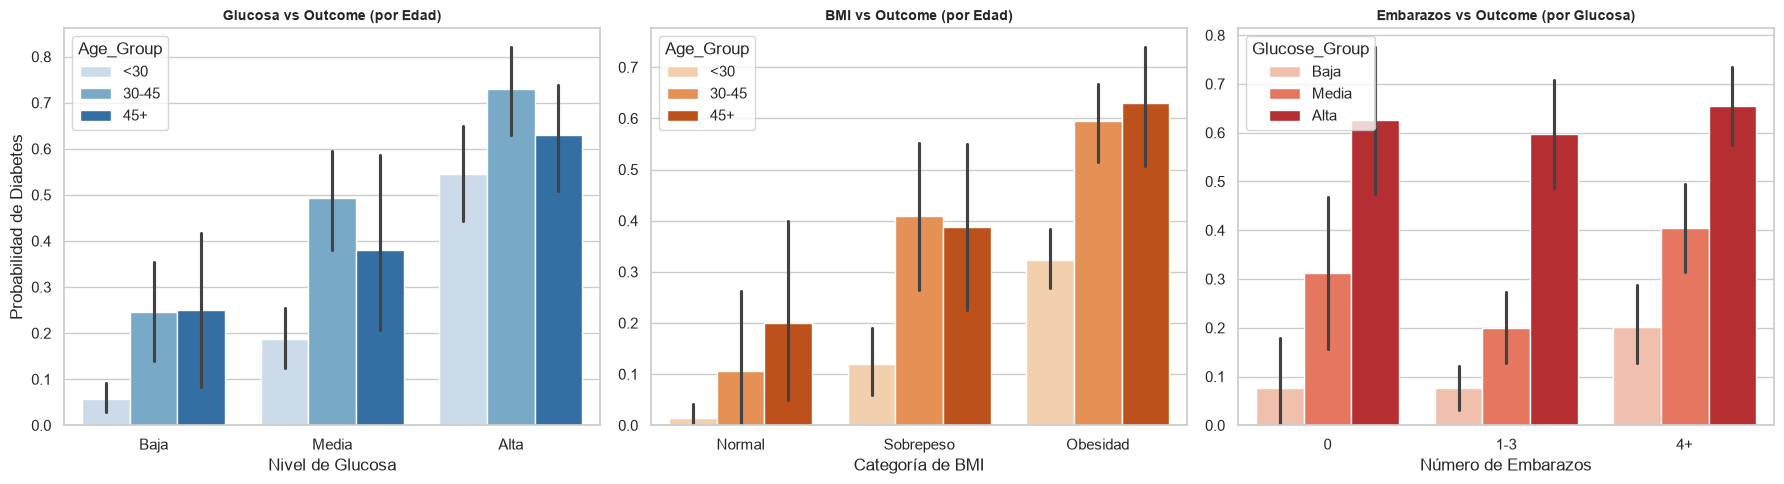

In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df_plot = df.copy()

# Convertimos Outcome a numérico si no lo está
if df_plot['Outcome'].dtype == 'object':
    df_plot['target_num'] = (
        df_plot['Outcome']
        .astype(str)
        .str.lower()
        .map({'yes': 1, 'no': 0, '1': 1, '0': 0})
    )
else:
    df_plot['target_num'] = df_plot['Outcome']

# Categorizamos variables continuas para poder usarlas como grupos en el barplot
df_plot['Age_Group'] = pd.cut(
    df_plot['Age'],
    bins=[0, 30, 45, 100],
    labels=['<30', '30-45', '45+'],
)
df_plot['Glucose_Group'] = pd.qcut(
    df_plot['Glucose'], q=3, labels=['Baja', 'Media', 'Alta']
)
df_plot['BMI_Group'] = pd.cut(
    df_plot['BMI'],
    bins=[0, 25, 30, 100],
    labels=['Normal', 'Sobrepeso', 'Obesidad'],
)
df_plot['Pregnancies_Group'] = pd.cut(
    df_plot['Pregnancies'],
    bins=[-1, 0, 3, 20],
    labels=['0', '1-3', '4+'],
)

# Configuración de la figura: 1 fila x 3 columnas
fig, axis = plt.subplots(figsize=(18, 5), ncols=3)

# 1. Glucose vs Outcome por Rango de Edad
sns.barplot(
    ax=axis[0],
    data=df_plot,
    x='Glucose_Group',
    y='target_num',
    hue='Age_Group',
    palette='Blues',
)
axis[0].set_title(
    'Glucosa vs Outcome (por Edad)', fontsize=10, fontweight='bold'
)
axis[0].set_ylabel('Probabilidad de Diabetes')
axis[0].set_xlabel('Nivel de Glucosa')

# 2. BMI vs Outcome por Rango de Edad
sns.barplot(
    ax=axis[1],
    data=df_plot,
    x='BMI_Group',
    y='target_num',
    hue='Age_Group',
    palette='Oranges',
)
axis[1].set_title('BMI vs Outcome (por Edad)', fontsize=10, fontweight='bold')
axis[1].set_xlabel('Categoría de BMI')
axis[1].set(ylabel=None)

# 3. Pregnancies vs Outcome por Nivel de Glucosa
sns.barplot(
    ax=axis[2],
    data=df_plot,
    x='Pregnancies_Group',
    y='target_num',
    hue='Glucose_Group',
    palette='Reds',
)
axis[2].set_title(
    'Embarazos vs Outcome (por Glucosa)', fontsize=10, fontweight='bold'
)
axis[2].set_xlabel('Número de Embarazos')
axis[2].set(ylabel=None)

# Ajustar el layout
plt.tight_layout()

# Mostrar el plot
plt.show()

Gráfico 1 (Glucosa vs. Outcome (por Edad)): Evalúa cómo interactúan los niveles de glucosa con los rangos de edad en el riesgo de padecer diabetes. 

La glucosa es el determinante dominante: Sin importar el grupo de edad, la probabilidad de diabetes pasa de niveles inferiores al 25% en la categoría "Baja" a rangos de 55% a 73% en la categoría "Alta".

Efecto de la edad intermedia: En el grupo de 30 a 45 años (30-45), un nivel de glucosa medio o alto dispara la probabilidad de diabetes a su punto máximo (~73% en glucosa alta), incluso superando ligeramente al grupo de mayores de 45 años (45+).

Protección relativa en jóvenes: Las personas menores de 30 años (<30) mantienen probabilidades bajas (~5%) con glucosa baja, pero si alcanzan niveles altos de glucosa, su riesgo sube drásticamente a más del 50%.

Gráfico 2 (BMI vs. Outcome (por Edad)): Muestra el impacto del nivel de peso (Normal, Sobrepeso, Obesidad) segmentado por grupo etario.

La obesidad multiplica el riesgo de forma crítica: En la categoría "Obesidad", la probabilidad de diabetes alcanza entre el 32% y el 63%, mientras que en peso "Normal" se mantiene casi en 0% para menores de 30 años y por debajo del 25% para el resto.

Sinergia entre Obesidad y Edad: Tener más de 30 años combinado con Obesidad eleva el riesgo a más del 60%, siendo el peso un acelerador clave de la enfermedad a medida que se cumple más edad.

Gráfico 3 (Embarazos vs. Outcome (por Glucosa)): Observa la relación entre el número de embarazos y el nivel de glucosa acumulado

La glucosa predomina sobre el número de embarazos: La diferencia principal en las barras la marca el color (nivel de glucosa) y no el número de embarazos. Tener Glucosa Alta garantiza una probabilidad de diabetes alrededor del 60% - 65%, sin importar si la persona tuvo 0, 1-3 o más de 4 embarazos.

Efecto acumulativo en glucosa media/baja: Para personas con glucosa Media o Baja, el aumento en el número de embarazos (4+) incrementa paulatinamente la probabilidad de diabetes (pasando de ~7% a ~20% en glucosa baja, y de ~30% a ~40% en glucosa media).

Síntesis General para el Modelado
Variables con mayor poder predictivo: Glucose y BMI son las variables con mayor capacidad de separación y efecto directo sobre Outcome.

Interacciones clave: Las combinaciones Glucose x Age y BMI x Age muestran fuertes efectos de interacción que conviene incluir o dejar aprender a modelos basados en árboles (como Random Forest o XGBoost).

In [21]:
# Vamos a reemplazar los valores 0 por NaN en las columnas que no deberían tener ceros (las biológicas), y luego imputaremos con la mediana de cada columna.

import numpy as np
import pandas as pd

# 1. Copia de seguridad del DataFrame original (opcional)
df_clean = df.copy()

# 2. Definir las variables donde un valor 0 no es biológicamente posible
cols_con_ceros_invalidos = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
]

# 3. Reemplazar los ceros (0) por NaN en las columnas seleccionadas
df_clean[cols_con_ceros_invalidos] = df_clean[
    cols_con_ceros_invalidos
].replace(0, np.nan)

# 4. Imputar los NaN usando la mediana calculada según la clase (Outcome: 0 o 1)
for col in cols_con_ceros_invalidos:
    df_clean[col] = df_clean[col].fillna(
        df_clean.groupby('Outcome')[col].transform('median')
    )

# 5. Verificación: Confirmar que ya no existen nulos ni valores cero
print('--- Verificación de Imputación ---')
print('Cantidad de ceros restantes:')
print((df_clean[cols_con_ceros_invalidos] == 0).sum())
print('\nCantidad de valores nulos (NaN) restantes:')
print(df_clean[cols_con_ceros_invalidos].isnull().sum())

--- Verificación de Imputación ---
Cantidad de ceros restantes:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

Cantidad de valores nulos (NaN) restantes:
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64


**Una vez que ya tenemos el EDA, tenemos limpias nuestras variables y podemos tener mejores variables para el modelo, lo realizamos:**

In [23]:
# ANTES hay que dividir en TRAIN y TEST:

from sklearn.model_selection import train_test_split

x = df.drop(columns=['Outcome']) # Nuestras variables predictoras son todas menos OUTCOME que es la v. a predecir
y = df['Outcome']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
x_train.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
60,2,84,0,0,0,0.0,0.304,21
618,9,112,82,24,0,28.2,1.282,50
346,1,139,46,19,83,28.7,0.654,22
294,0,161,50,0,0,21.9,0.254,65
231,6,134,80,37,370,46.2,0.238,46


Se hizo bien, se seleccionaron distintos índices en un orden aleatorio y no tenemos la variable a predecir 'Outcome'. Tenemos listos nuestros conjuntos de TRAIN y TEST (no los tenemos que normalizar).

**Vamos a elegir "DecisionTreClassifier" y no "Regression" porque en este caso la variable que estoy tratando de predecir es tiene o no tiene diabétes, que se reflejan en = 0 y 1 respectivamente.**

In [25]:
# Realización del Modelo: 

from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(random_state=42)
model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

Con esto obtenemos nuestro modelo. Tenemos los parámetros con los que está entrenado, que en este caso es 'Gini' de criterio, y hay distintos hiperparámetros que se pueden usar, están todos ahí, y también están nuestros atributos. Ya podemos ver qué se usó para entrenar el modelo.

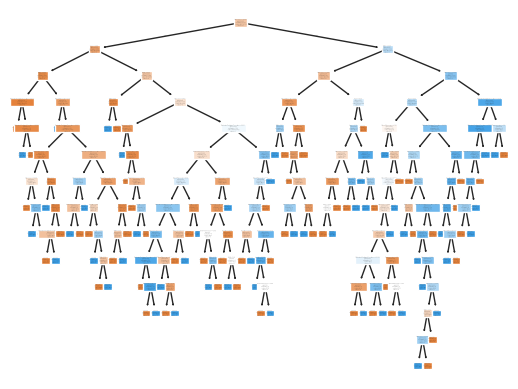

In [26]:
# podemos graficar este arbol:

from sklearn.tree import plot_tree  
import matplotlib.pyplot as plt

plot_tree(model, feature_names= list(x_train.columns), class_names=["0", "1"], filled= True)

plt.show()

Podemos visualizar el árbol de decisión. Lo dejamos sobreajustarse sin límites, todo lo que era posible sobreajustarse.

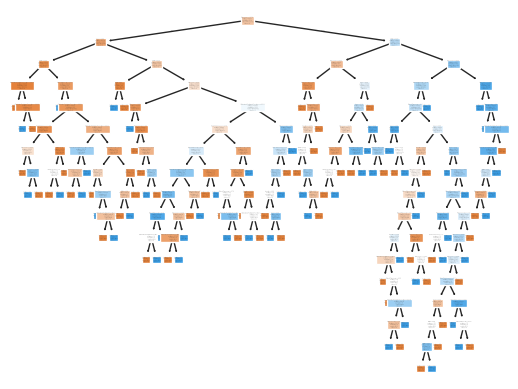

In [27]:
model_entropia = DecisionTreeClassifier(criterion='entropy', random_state=42)
model_log_loss = DecisionTreeClassifier(criterion='log_loss', random_state=42)

# Ahí tenemos los modelos, los vamos a entrenar:

model_entropia.fit(x_train, y_train)
model_log_loss.fit(x_train, y_train)

# Y luego los vamos a graficar:

plot_tree(model_entropia, feature_names= list(x_train.columns), class_names=["0", "1"], filled= True)

plt.show()

Sí hay un cambio respecto del otro gráfico. 

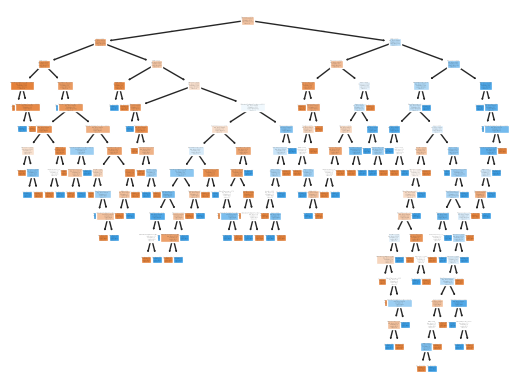

In [28]:
plot_tree(model_log_loss, feature_names= list(x_train.columns), class_names=["0", "1"], filled= True)

plt.show()

In [30]:
# Para ver cómo se comporta el modelo: 

y_pred = model.predict(x_test)
y_pred_entropia = model_entropia.predict(x_test)
y_pred_log_loss = model_log_loss.predict(x_test)

# Y acá tenemos todas nuestras predicciones. No son fáciles de ver pero sí de medir. Vamos a usar accuracy.

from sklearn.metrics import accuracy_score

print(f'Precisión Árbol de Decisión en Gini: {accuracy_score(y_test, y_pred)}')
print(f'Precisión Árbol de Decisión en Entropía: {accuracy_score(y_test, y_pred_entropia)}')
print(f'Precisión Árbol de Decisión en Pérdida Log: {accuracy_score(y_test, y_pred_log_loss)}')

Precisión Árbol de Decisión en Gini: 0.7467532467532467
Precisión Árbol de Decisión en Entropía: 0.7207792207792207
Precisión Árbol de Decisión en Pérdida Log: 0.7207792207792207


Podemos ver que el modelo hecho con 'Gini' tiene un 74.6 % de predicción, de cada 4 predicciones, 3 son correctas, lo cual es una predicción muy buena. 

In [15]:
# Tenemos que hacer una hiperparametrización y para eso, lo primero que necesito es una grilla.

param_grid = {
    #Criterios para medir la calidad de la división:
    'criterion': ['gini', 'entropy', 'log_loss'],

    # Estrategia usada para elegir la división en cada nodo:
    'splitter': ['best', 'random'],

    # Profundidad máxima del árbol (controla el sobreajuste)
    'max_depth': [None, 3, 5, 7, 10, 15, 20],

    # Número mínimo de muestras requeridas para dividir un nodo interno:
    'min_samples_split': [2, 5, 10, 20],

    # Número mínimo de muestras requeridas en un nodo hoja:
    'min_samples_leaf': [1, 2, 4, 8],

    # Número máximo de características a considerar al buscar la mejor división:
    'max_features': [None, 'sqrt', 'log2']
}

In [16]:
# para implementar esta grilla: 

from sklearn.model_selection import GridSearchCV

gride_search = GridSearchCV(
    estimator= model,
    param_grid= param_grid,
    cv= 5,
    scoring= 'accuracy',
    n_jobs=-1
)

In [17]:
# Hasta acá tenemos nuestra grilla definida.

gride_search.fit(x_train, y_train)

C:\Users\brend\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'criterion': ['gini', 'entropy', ...], 'max_depth': [None, 3, ...], 'max_features': [None, 'sqrt', ...], 'min_samples_leaf': [1, 2, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for call

In [18]:
print(f'Mejores Parámetros: (gride_search.bestparams_)')
print(f'Mejor accuracy:(grid_search.best_score_)')

mejor_modelo = grid_search.best_estimator_

Mejores Parámetros: (gride_search.bestparams_)
Mejor accuracy:(grid_search.best_score_)


NameError: name 'grid_search' is not defined

In [ ]:
# Y lo guardamos: 

from pickle import dump

dump(mejor_modelo, open("../models/decission_tree_grid_search_42.model", "wb"))